In [26]:
import random
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

# --- reproducibility: fix the seed so your reported numbers reproduce -------
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- device: train on the GPU if Colab gave you one -------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then re-run.")


@torch.no_grad()
def accuracy(logits, y):
    """Fraction correct for a batch of class logits vs integer labels."""
    return (logits.argmax(dim=-1) == y).float().mean().item()


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    """One no-grad pass over `loader`; returns (mean loss, accuracy)."""
    model.eval()                                  # dropout off, BN uses running stats
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)         # same device as the model
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(dim=-1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def train(model, train_loader, val_loader, *, epochs=10, lr=1e-3,
          weight_decay=0.0, loss_fn=None, max_grad_norm=None):
    """The five-step loop (forward, loss, zero_grad, backward, step) with a
    validation pass each epoch. Returns a per-epoch history dict."""
    model = model.to(device)                      # move the model once, before the loop
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:                 # the five steps, per batch
            x, y = x.to(device), y.to(device)     # data on the SAME device as the model
            logits = model(x)                     # 1. forward
            loss = loss_fn(logits, y)             # 2. loss
            optimizer.zero_grad()                 # 3. clear last batch's grads
            loss.backward()                       # 4. backprop
            if max_grad_norm is not None:         # clip for RNNs/LSTMs (Track B)
                nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()                      # 5. update the weights

        tr_loss, tr_acc = evaluate(model, train_loader, loss_fn)
        va_loss, va_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        print(f"epoch {epoch + 1:2d}/{epochs}  "
              f"train_loss={tr_loss:.3f} acc={tr_acc:.2%}  |  "
              f"val_loss={va_loss:.3f} acc={va_acc:.2%}")
    return history


def plot_curves(history):
    """Train vs. validation loss and accuracy — read the gap (labs L5/L11)."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(epochs, history["train_loss"], "-o", label="train")
    ax1.plot(epochs, history["val_loss"], "-o", label="val")
    ax1.set(xlabel="epoch", ylabel="loss", title="Loss")
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(epochs, history["train_acc"], "-o", label="train")
    ax2.plot(epochs, history["val_acc"], "-o", label="val")
    ax2.set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


print("spine ready: accuracy(), evaluate(), train(), plot_curves()")

device: cuda
spine ready: accuracy(), evaluate(), train(), plot_curves()


In [25]:
# Section 2: Dataset loading, cleaning, and splitting

from datasets import load_dataset, Image as HFImage
from sklearn.model_selection import train_test_split
from io import BytesIO
from PIL import Image
from pathlib import Path
import numpy as np

DATASET_ID = "hassanjbara/AI4MARS"
SEED = 0
IMAGE_SIZE = (256, 256)
NUM_CLASSES = 4
IGNORE_INDEX = 255
CLASS_NAMES = ["Soil", "Bedrock", "Sand", "Big rock"]

# Load the dataset.
train_data = load_dataset(DATASET_ID, split="train")

# Inspect encoded image fields without decoding every image automatically.
raw_data = train_data.select_columns(
    ["image", "label_mask", "has_labels"]
).cast_column(
    "image", HFImage(decode=False)
).cast_column(
    "label_mask", HFImage(decode=False)
)

def decode_image_field(value):
    if value is None:
        return None

    if value.get("bytes") is not None:
        return Image.open(BytesIO(value["bytes"])).copy()

    if value.get("path"):
        return Image.open(value["path"]).copy()

    raise ValueError("Image has neither bytes nor a path.")

usable_indices = []
bad_image_indices = []
missing_mask_indices = []
empty_mask_indices = []

for idx in range(len(raw_data)):
    row = raw_data[idx]

    try:
        image = decode_image_field(row["image"])
        image.close()
    except Exception:
        bad_image_indices.append(idx)
        continue

    if not row["has_labels"] or row["label_mask"] is None:
        missing_mask_indices.append(idx)
        continue

    mask = decode_image_field(row["label_mask"]).convert("L")
    valid_pixels = np.any(np.asarray(mask) != IGNORE_INDEX)
    mask.close()

    if not valid_pixels:
        empty_mask_indices.append(idx)
        continue

    usable_indices.append(idx)

train_indices, val_indices = train_test_split(
    usable_indices,
    test_size=0.20,
    random_state=SEED,
    shuffle=True,
)

train_subset = train_data.select(train_indices)
val_subset = train_data.select(val_indices)

print("Total records:", len(train_data))
print("Usable records:", len(usable_indices))
print("Broken images:", len(bad_image_indices))
print("Missing masks:", len(missing_mask_indices))
print("Empty masks:", len(empty_mask_indices))
print("Training:", len(train_subset))
print("Validation:", len(val_subset))

assert set(train_indices).isdisjoint(val_indices)
assert len(train_indices) + len(val_indices) == len(usable_indices)

README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

data/train-00000-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  475MB            

data/train-00000-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  476MB            

data/train-00001-of-00013.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/18130 [00:00<?, ? examples/s]

Generating test_min1 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Generating test_min2 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Generating test_min3 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Total records: 18130
Usable records: 15901
Broken images: 3
Missing masks: 2063
Empty masks: 163
Training: 12720
Validation: 3181


In [27]:
# Section 3: PyTorch dataset and data loaders

import torch
from torch.utils.data import Dataset, DataLoader

class MarsTerrainDataset(Dataset):
    def __init__(self, hf_dataset, image_size=IMAGE_SIZE):
        self.data = hf_dataset
        self.image_size = image_size

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data[idx]

        image = row["image"].convert("L")
        mask = row["label_mask"].convert("L")

        image = image.resize(
            self.image_size,
            Image.Resampling.BILINEAR,
        )
        mask = mask.resize(
            self.image_size,
            Image.Resampling.NEAREST,
        )

        image_array = np.asarray(image, dtype=np.float32) / 255.0
        mask_array = np.asarray(mask, dtype=np.int64)

        x = torch.from_numpy(image_array.copy()).unsqueeze(0)
        y = torch.from_numpy(mask_array.copy())

        return x, y


train_dataset = MarsTerrainDataset(train_subset)
val_dataset = MarsTerrainDataset(val_subset)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

# Sanity check one batch.
images, masks = next(iter(train_loader))

print("Image batch:", images.shape)
print("Mask batch:", masks.shape)
print("Mask values:", torch.unique(masks).tolist())

assert images.shape[1:] == (1, 256, 256)
assert masks.shape[1:] == (256, 256)
assert torch.all(
    (masks == IGNORE_INDEX) |
    ((masks >= 0) & (masks < NUM_CLASSES))
)

print("Dataset pipeline checks passed.")

Image batch: torch.Size([16, 1, 256, 256])
Mask batch: torch.Size([16, 256, 256])
Mask values: [0, 1, 2, 3, 255]
Dataset pipeline checks passed.


Sample 0: image=(1, 256, 256), mask=(256, 256), labels=[0, 1, 2, 255], labeled coverage=34.9%
Sample 1: image=(1, 256, 256), mask=(256, 256), labels=[1, 3, 255], labeled coverage=62.2%
Sample 2: image=(1, 256, 256), mask=(256, 256), labels=[1, 255], labeled coverage=82.9%


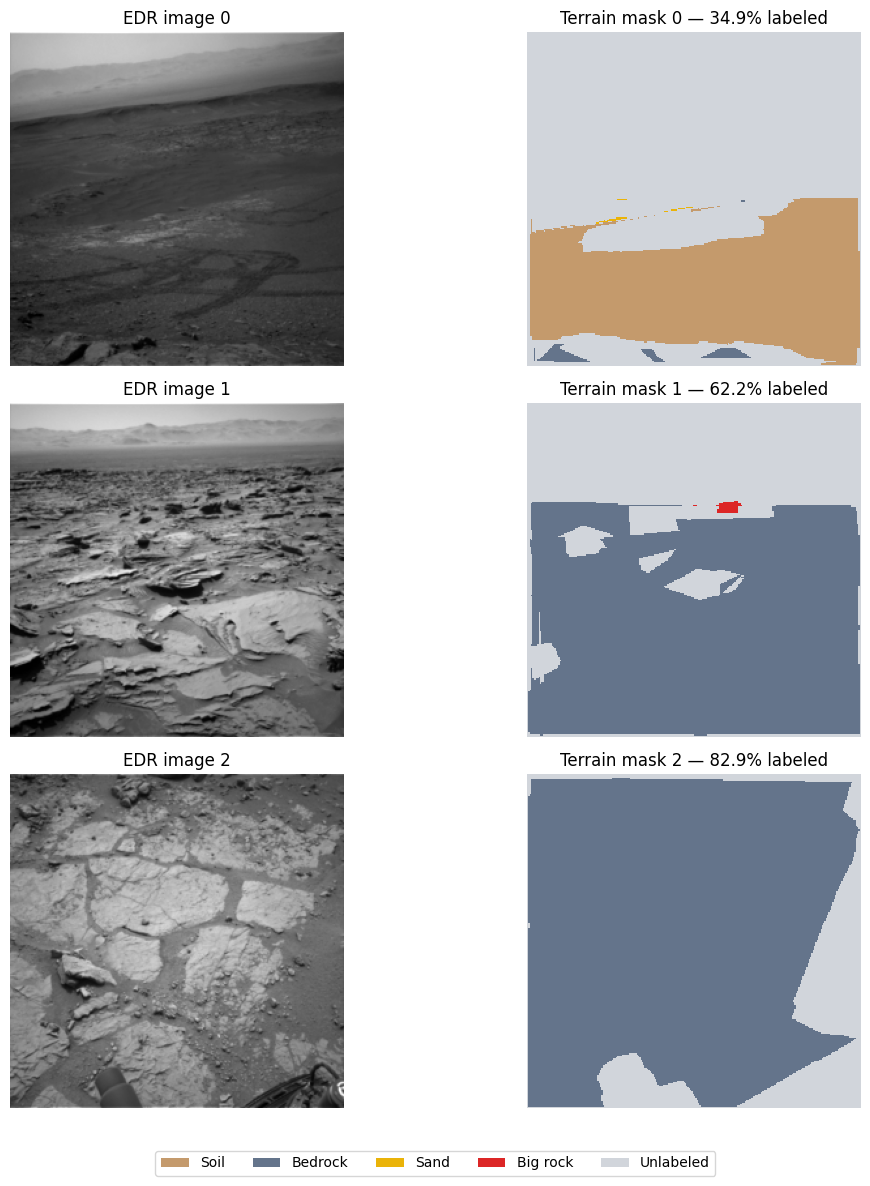

In [28]:

# Cell C: Visualize training images and terrain masks

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

CLASS_NAMES = {
    0: "Soil",
    1: "Bedrock",
    2: "Sand",
    3: "Big rock",
}

# Visualization colors only; original label IDs remain unchanged.
terrain_cmap = ListedColormap([
    "#c49a6c",  # Soil
    "#64748b",  # Bedrock
    "#eab308",  # Sand
    "#dc2626",  # Big rock
])
terrain_cmap.set_bad(color="#d1d5db")  # Unlabeled pixels

NUM_SAMPLES = 3

fig, axes = plt.subplots(
    NUM_SAMPLES, 2,
    figsize=(12, 4 * NUM_SAMPLES),
    squeeze=False,
)

for i in range(NUM_SAMPLES):
    image_tensor, mask_tensor = train_dataset[i]

    image = image_tensor.squeeze(0).numpy()
    mask = mask_tensor.numpy()

    labels = torch.unique(mask_tensor).tolist()
    valid = mask != IGNORE_INDEX
    coverage = valid.mean() * 100

    print(
        f"Sample {i}: "
        f"image={tuple(image_tensor.shape)}, "
        f"mask={tuple(mask_tensor.shape)}, "
        f"labels={labels}, "
        f"labeled coverage={coverage:.1f}%"
    )

    # Original grayscale EDR image
    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title(f"EDR image {i}")
    axes[i, 0].axis("off")

    # Terrain mask, with unlabeled pixels shown in gray
    display_mask = np.ma.masked_equal(mask, IGNORE_INDEX)

    axes[i, 1].imshow(
        display_mask,
        cmap=terrain_cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest",
    )
    axes[i, 1].set_title(
        f"Terrain mask {i} — {coverage:.1f}% labeled"
    )
    axes[i, 1].axis("off")

legend_items = [
    Patch(facecolor=terrain_cmap(i), label=name)
    for i, name in CLASS_NAMES.items()
]
legend_items.append(
    Patch(facecolor="#d1d5db", label="Unlabeled")
)

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=5,
    bbox_to_anchor=(0.5, 0.01),
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


In [29]:
# Cell D: Majority-Class Baseline

import torch

NUM_CLASSES = 4
CLASS_NAMES = ["Soil", "Bedrock", "Sand", "Big rock"]
IGNORE_INDEX = 255

# 1. Find the majority class from TRAINING masks only
class_counts = torch.zeros(NUM_CLASSES, dtype=torch.long)

for _, masks in train_loader:
    for class_id in range(NUM_CLASSES):
        class_counts[class_id] += (masks == class_id).sum().item()

majority_class = class_counts.argmax().item()

print("Training pixel distribution:")
for class_id, name in enumerate(CLASS_NAMES):
    percentage = (
        class_counts[class_id].item()
        / class_counts.sum().item()
        * 100
    )
    print(f"{name:10s}: {percentage:6.2f}%")

print(f"\nMajority class: {CLASS_NAMES[majority_class]}")


# 2. Evaluate the baseline on validation data
confusion_matrix = torch.zeros(
    NUM_CLASSES, NUM_CLASSES, dtype=torch.long
)

with torch.no_grad():
    for _, masks in val_loader:
        targets = masks.cpu().long()

        # Exclude unlabeled pixels
        valid = targets != IGNORE_INDEX
        targets = targets[valid]

        if targets.numel() == 0:
            continue

        # Predict the majority class for every valid pixel
        predictions = torch.full_like(targets, majority_class)

        # Rows = true classes, columns = predicted classes
        indices = targets * NUM_CLASSES + predictions
        confusion_matrix += torch.bincount(
            indices,
            minlength=NUM_CLASSES**2
        ).reshape(NUM_CLASSES, NUM_CLASSES)


# 3. Calculate metrics
true_positives = confusion_matrix.diag().float()
actual_counts = confusion_matrix.sum(dim=1).float()
predicted_counts = confusion_matrix.sum(dim=0).float()

union = actual_counts + predicted_counts - true_positives

iou = torch.full((NUM_CLASSES,), float("nan"))
present_classes = union > 0
iou[present_classes] = (
    true_positives[present_classes] / union[present_classes]
)

total_pixels = confusion_matrix.sum().item()
pixel_accuracy = true_positives.sum().item() / total_pixels
mean_iou = iou[present_classes].mean().item()


# 4. Display results
print("\n=== Majority-Class Baseline Results ===")
print(f"Pixel Accuracy: {pixel_accuracy:.4f}")
print(f"Mean IoU:       {mean_iou:.4f}")

print("\nPer-class IoU:")
for class_id, name in enumerate(CLASS_NAMES):
    value = iou[class_id].item()
    if torch.isnan(iou[class_id]):
        print(f"{name:10s}: N/A")
    else:
        print(f"{name:10s}: {value:.4f}")

print("\nConfusion Matrix (rows=true, columns=predicted):")
print(confusion_matrix)


Training pixel distribution:
Soil      :  37.09%
Bedrock   :  49.92%
Sand      :  12.07%
Big rock  :   0.93%

Majority class: Bedrock

=== Majority-Class Baseline Results ===
Pixel Accuracy: 0.4936
Mean IoU:       0.1234

Per-class IoU:
Soil      : 0.0000
Bedrock   : 0.4936
Sand      : 0.0000
Big rock  : 0.0000

Confusion Matrix (rows=true, columns=predicted):
tensor([[       0, 44681476,        0,        0],
        [       0, 58277232,        0,        0],
        [       0, 14048790,        0,        0],
        [       0,  1067841,        0,        0]])


In [30]:
# Cell E: Save Experiment Manifest

import json
from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Create output directory
OUTPUT_DIR = Path("/content/drive/MyDrive/AI4Mars_Project")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Collect experiment settings and results for reproducibility
manifest = {
    "dataset_id": DATASET_ID,
    "seed": SEED,
    "image_size": list(IMAGE_SIZE),
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "ignore_index": IGNORE_INDEX,
    "split_method": "random record-level 80/20 split",

    # Dataset split
    "train_indices": [int(i) for i in train_indices],
    "validation_indices": [int(i) for i in val_indices],

    # Excluded records
    "excluded_bad_image_indices": [
        int(i) for i in bad_image_indices
    ],
    "excluded_missing_mask_indices": [
        int(i) for i in missing_mask_indices
    ],
    "excluded_empty_mask_indices": [
        int(i) for i in empty_mask_indices
    ],

    # Majority-class baseline results
    "baseline": {
        "majority_class": CLASS_NAMES[majority_class],
        "pixel_accuracy": float(baseline_accuracy),
        "mean_iou": float(baseline_miou),
        "train_pixel_counts": train_counts.tolist(),
        "validation_pixel_counts": val_counts.tolist(),
    },
}

# Save manifest as JSON
manifest_path = OUTPUT_DIR / "experiment_manifest.json"

with manifest_path.open("w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print(f"Manifest saved to: {manifest_path}")
print(f"Training records:   {len(train_indices):,}")
print(f"Validation records: {len(val_indices):,}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


NameError: name 'baseline_accuracy' is not defined

In [31]:
import torch
import torch.nn as nn


class DoubleConv(nn.Module):
    """Two convolution layers with BatchNorm and ReLU."""

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """Compact U-Net for semantic segmentation."""

    def __init__(self, in_channels=3, num_classes=4, base_channels=32):
        super().__init__()

        # Encoder: learn features while reducing spatial dimensions.
        self.enc1 = DoubleConv(in_channels, base_channels)
        self.enc2 = DoubleConv(base_channels, base_channels * 2)
        self.enc3 = DoubleConv(base_channels * 2, base_channels * 4)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Bottleneck: deepest feature representation.
        self.bottleneck = DoubleConv(
            base_channels * 4, base_channels * 8
        )

        # Decoder: upsample and combine encoder features.
        self.up3 = nn.ConvTranspose2d(
            base_channels * 8, base_channels * 4, 2, stride=2
        )
        self.dec3 = DoubleConv(base_channels * 8, base_channels * 4)

        self.up2 = nn.ConvTranspose2d(
            base_channels * 4, base_channels * 2, 2, stride=2
        )
        self.dec2 = DoubleConv(base_channels * 4, base_channels * 2)

        self.up1 = nn.ConvTranspose2d(
            base_channels * 2, base_channels, 2, stride=2
        )
        self.dec1 = DoubleConv(base_channels * 2, base_channels)

        # One output logit channel per terrain class.
        self.head = nn.Conv2d(base_channels, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Bottleneck
        b = self.bottleneck(self.pool(e3))

        # Decoder + skip connections
        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.head(d1)

In [32]:
# Use the professor's device variable if you already defined it.
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = UNet(
    in_channels=3,
    num_classes=4,
    base_channels=32
).to(device)

# Simulate a batch of 2 RGB images at 256x256.
dummy_images = torch.randn(2, 3, 256, 256, device=device)

model.train()
logits = model(dummy_images)

print("Device:", device)
print("Input shape:", dummy_images.shape)
print("Output shape:", logits.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

# Verify the forward and backward passes.
dummy_masks = torch.randint(
    0, 4, (2, 256, 256), device=device
)
loss = nn.CrossEntropyLoss()(logits, dummy_masks)
loss.backward()

print("Dummy loss:", loss.item())
print("Backward pass successful!")

Device: cuda
Input shape: torch.Size([2, 3, 256, 256])
Output shape: torch.Size([2, 4, 256, 256])
Trainable parameters: 1927108
Dummy loss: 1.4413542747497559
Backward pass successful!


In [33]:
import torch

images, masks = next(iter(train_loader))

print("Device:", device)
print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Image shape:", images.shape)
print("Mask shape:", masks.shape)
print("Image range:", images.min().item(), images.max().item())
print("Mask values:", torch.unique(masks).tolist())
print("NUM_CLASSES:", NUM_CLASSES)
print("IGNORE_INDEX:", IGNORE_INDEX)

assert images.ndim == 4
assert images.shape[1] == 1
assert masks.ndim == 3
assert images.shape[0] == masks.shape[0]
assert torch.isfinite(images).all()
assert torch.all(
    (masks == IGNORE_INDEX) |
    ((masks >= 0) & (masks < NUM_CLASSES))
)

print("Batch checks passed.")

Device: cuda
Train samples: 12720
Validation samples: 3181
Image shape: torch.Size([16, 1, 256, 256])
Mask shape: torch.Size([16, 256, 256])
Image range: 0.003921568859368563 0.9843137264251709
Mask values: [0, 1, 2, 3, 255]
NUM_CLASSES: 4
IGNORE_INDEX: 255
Batch checks passed.


In [34]:
model = UNet(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=32,
).to(device)

print("Model input channels:", model.enc1.block[0].in_channels)

Model input channels: 1


In [35]:
import torch.nn as nn

images, masks = next(iter(train_loader))
images = images.to(device)
masks = masks.to(device)

model.train()
logits = model(images)

criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
loss = criterion(logits, masks)

print("Logits:", logits.shape)
print("Loss:", loss.item())

assert logits.shape == (
    images.shape[0],
    NUM_CLASSES,
    images.shape[2],
    images.shape[3],
)

assert torch.isfinite(loss), "Loss is not finite!"

print("Real-data forward pass successful.")

Logits: torch.Size([16, 4, 256, 256])
Loss: 1.422160267829895
Real-data forward pass successful.


In [36]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# Reproducible debugging test
torch.manual_seed(SEED)

# Use a fixed batch of 4 real training samples.
tiny_loader = DataLoader(
    torch.utils.data.Subset(train_dataset, [0, 1, 2, 3]),
    batch_size=4,
    shuffle=False,
    num_workers=0,
)

images, masks = next(iter(tiny_loader))
images = images.to(device)
masks = masks.to(device)

valid_pixels = masks != IGNORE_INDEX
assert valid_pixels.any(), "Batch contains no valid labeled pixels."

# Separate model: do not reuse this model for final training.
overfit_model = UNet(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=32,
).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.Adam(overfit_model.parameters(), lr=1e-3)

loss_history = []

overfit_model.train()

for step in range(51):
    optimizer.zero_grad(set_to_none=True)

    logits = overfit_model(images)
    loss = criterion(logits, masks)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if step % 10 == 0:
        print(f"Step {step:02d} | Loss: {loss.item():.4f}")

print("\nInitial loss:", round(loss_history[0], 4))
print("Final loss:  ", round(loss_history[-1], 4))

Step 00 | Loss: 1.1656
Step 10 | Loss: 0.4283
Step 20 | Loss: 0.2655
Step 30 | Loss: 0.1715
Step 40 | Loss: 0.1217
Step 50 | Loss: 0.0881

Initial loss: 1.1656
Final loss:   0.0881
